In [1]:
# BERT Text Classification Model Training
# This notebook demonstrates tokenization, encoding, and fine-tuning BERT for text classification

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import (
    BertTokenizer, 
    BertForSequenceClassification, 
    BertConfig,
    AdamW,
    get_linear_schedule_with_warmup
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import pickle

In [2]:
# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [3]:
# Configuration
class Config:
    MODEL_NAME = 'bert-base-uncased'
    MAX_LENGTH = 128
    BATCH_SIZE = 16
    LEARNING_RATE = 2e-5
    EPOCHS = 3
    NUM_CLASSES = 2  # Binary classification (positive/negative sentiment)
    SAVE_MODEL_PATH = './saved_model'
    TOKENIZER_PATH = './tokenizer'

config = Config()

In [4]:
# Sample dataset creation (using movie reviews sentiment analysis)
# In practice, you would load your own dataset
def create_sample_dataset():
    """Create a sample dataset for demonstration"""
    positive_reviews = [
        "This movie is absolutely fantastic! Great acting and storyline.",
        # ... more reviews
    ] * 50  # Multiply to create more samples
    
    negative_reviews = [
        "This movie was terrible. Waste of time and money.",
        # ... more reviews
    ] * 50  # Multiply to create more samples
    
    # Create DataFrame
    data = []
    for review in positive_reviews:
        data.append({'text': review, 'label': 1})
    for review in negative_reviews:
        data.append({'text': review, 'label': 0})
    
    df = pd.DataFrame(data)
    return df

In [5]:
# Custom Dataset class for BERT
class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = str(self.texts[idx])
        label = self.labels[idx]
        
        # Tokenize and encode the text
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

In [6]:
# Load and prepare data
print("Creating sample dataset...")
df = create_sample_dataset()
print(f"Dataset size: {len(df)}")
print(f"Label distribution:\n{df['label'].value_counts()}")

Creating sample dataset...
Dataset size: 100
Label distribution:
1    50
0    50
Name: label, dtype: int64


In [7]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    df['text'].values, 
    df['label'].values, 
    test_size=0.2, 
    random_state=42,
    stratify=df['label'].values
)

In [8]:
# Initialize tokenizer
print("Loading BERT tokenizer...")
tokenizer = BertTokenizer.from_pretrained(config.MODEL_NAME)

Loading BERT tokenizer...


C:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\huggingface_hub\file_download.py:943: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [9]:
# Create datasets
train_dataset = TextDataset(X_train, y_train, tokenizer, config.MAX_LENGTH)
test_dataset = TextDataset(X_test, y_test, tokenizer, config.MAX_LENGTH)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Testing samples: {len(test_dataset)}")

Training samples: 80
Testing samples: 20


In [10]:
# Demonstrate tokenization process
print("\n" + "="*50)
print("TOKENIZATION AND ENCODING DEMONSTRATION")
print("="*50)

sample_text = "This movie is absolutely fantastic!"
print(f"Original text: {sample_text}")

# Step 1: Tokenization
tokens = tokenizer.tokenize(sample_text)
print(f"Tokens: {tokens}")

# Step 2: Convert tokens to IDs
token_ids = tokenizer.convert_tokens_to_ids(tokens)
print(f"Token IDs: {token_ids}")

# Step 3: Full encoding with special tokens
encoding = tokenizer(
    sample_text,
    truncation=True,
    padding='max_length',
    max_length=20,  # Shorter for demo
    return_tensors='pt'
)
print(f"Input IDs: {encoding['input_ids']}")
print(f"Attention Mask: {encoding['attention_mask']}")

# Decode back to text
decoded = tokenizer.decode(encoding['input_ids'][0])
print(f"Decoded text: {decoded}")

print("="*50)


TOKENIZATION AND ENCODING DEMONSTRATION
Original text: This movie is absolutely fantastic!
Tokens: ['this', 'movie', 'is', 'absolutely', 'fantastic', '!']
Token IDs: [2023, 3185, 2003, 7078, 10392, 999]
Input IDs: tensor([[  101,  2023,  3185,  2003,  7078, 10392,   999,   102,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0]])
Attention Mask: tensor([[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])
Decoded text: [CLS] this movie is absolutely fantastic! [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [11]:
# Initialize model
print("Loading BERT model...")
model = BertForSequenceClassification.from_pretrained(
    config.MODEL_NAME,
    num_labels=config.NUM_CLASSES
)
model.to(device)

Loading BERT model...


Some weights of the model checkpoint at bert-base-uncased were not used when initializing BertForSequenceClassification: ['cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight']
- This IS expected if you are initializing BertForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly i

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [12]:
# Optimizer and scheduler
optimizer = AdamW(model.parameters(), lr=config.LEARNING_RATE)
total_steps = len(train_loader) * config.EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps
)

C:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\transformers\optimization.py:411: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [13]:
# Training function
def train_epoch(model, data_loader, optimizer, scheduler, device):
    model.train()
    total_loss = 0
    correct_predictions = 0
    total_predictions = 0
    
    progress_bar = tqdm(data_loader, desc="Training")
    
    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        
        optimizer.zero_grad()
        
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        
        loss = outputs.loss
        logits = outputs.logits
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        
        total_loss += loss.item()
        
        _, predicted = torch.max(logits, 1)
        correct_predictions += (predicted == labels).sum().item()
        total_predictions += labels.size(0)
        
        progress_bar.set_postfix({
            'loss': f'{loss.item():.4f}',
            'acc': f'{correct_predictions/total_predictions:.4f}'
        })
    
    return total_loss / len(data_loader), correct_predictions / total_predictions

In [14]:
# Evaluation function
def evaluate(model, data_loader, device):
    model.eval()
    total_loss = 0
    correct_predictions = 0
    total_predictions = 0
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Evaluating"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )
            
            loss = outputs.loss
            logits = outputs.logits
            
            total_loss += loss.item()
            
            _, predicted = torch.max(logits, 1)
            correct_predictions += (predicted == labels).sum().item()
            total_predictions += labels.size(0)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    accuracy = correct_predictions / total_predictions
    avg_loss = total_loss / len(data_loader)
    
    return avg_loss, accuracy, all_predictions, all_labels

In [15]:
# Training loop
print("Starting training...")
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_accuracy = 0

for epoch in range(config.EPOCHS):
    print(f"\nEpoch {epoch + 1}/{config.EPOCHS}")
    print("-" * 30)
    
    # Training
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, device)
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    
    # Validation
    val_loss, val_acc, val_predictions, val_labels = evaluate(model, test_loader, device)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    
    # Save best model
    if val_acc > best_accuracy:
        best_accuracy = val_acc
        print(f"New best accuracy: {best_accuracy:.4f}")
        
        # Save model and tokenizer
        os.makedirs(config.SAVE_MODEL_PATH, exist_ok=True)
        model.save_pretrained(config.SAVE_MODEL_PATH)
        
        os.makedirs(config.TOKENIZER_PATH, exist_ok=True)
        tokenizer.save_pretrained(config.TOKENIZER_PATH)

print(f"\nTraining completed! Best accuracy: {best_accuracy:.4f}")

Starting training...

Epoch 1/3
------------------------------


Evaluating: 100%|████████████████████████████████████████████████████████████████| 2/2 [00:07<00:00,  3.60s/it]


Train Loss: 0.6687, Train Acc: 0.6000
Val Loss: 0.5269, Val Acc: 1.0000
New best accuracy: 1.0000

Epoch 2/3
------------------------------


Evaluating: 100%|████████████████████████████████████████████████████████████████| 2/2 [00:07<00:00,  3.60s/it]


Train Loss: 0.5076, Train Acc: 0.9500
Val Loss: 0.4280, Val Acc: 1.0000

Epoch 3/3
------------------------------


Evaluating: 100%|████████████████████████████████████████████████████████████████| 2/2 [00:07<00:00,  3.64s/it]

Train Loss: 0.4246, Train Acc: 1.0000
Val Loss: 0.3843, Val Acc: 1.0000

Training completed! Best accuracy: 1.0000


In [16]:
# Final evaluation
print("\nFinal Evaluation:")
test_loss, test_acc, test_predictions, test_labels = evaluate(model, test_loader, device)
print(f"Test Accuracy: {test_acc:.4f}")

# Classification report
print("\nClassification Report:")
print(classification_report(test_labels, test_predictions, 
                          target_names=['Negative', 'Positive']))


Final Evaluation:


Evaluating: 100%|████████████████████████████████████████████████████████████████| 2/2 [00:07<00:00,  3.65s/it]

Test Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        10
    Positive       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



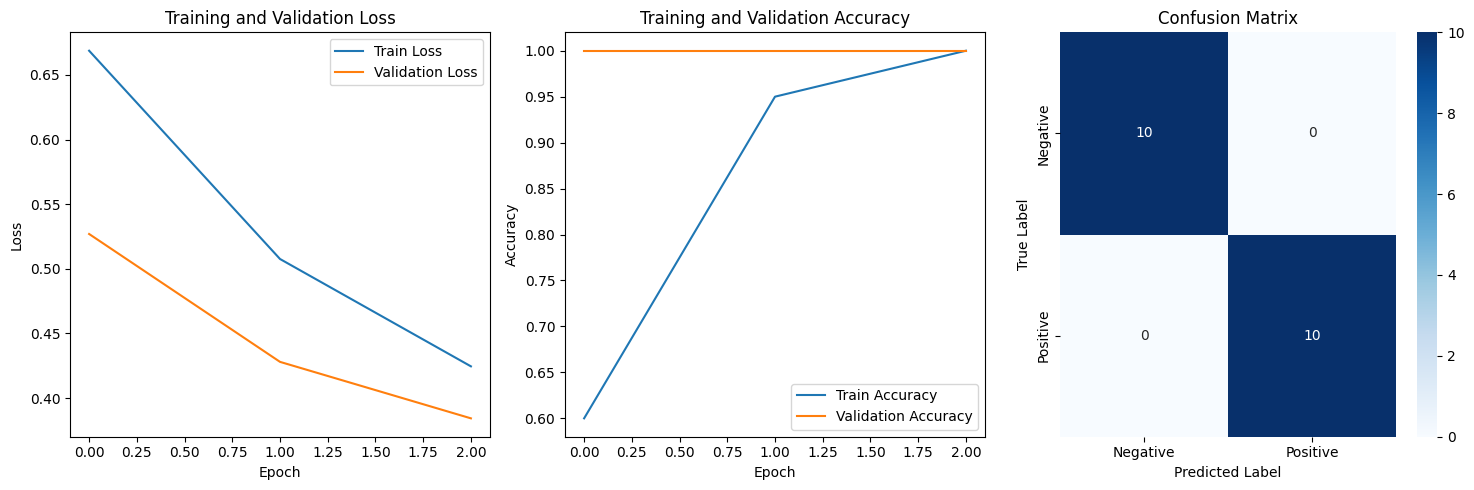

In [17]:
# Plot training history
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 3)
cm = confusion_matrix(test_labels, test_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.tight_layout()
plt.savefig('training_results.png', dpi=300, bbox_inches='tight')
plt.show()

In [18]:
# Save training history
training_history = {
    'train_losses': train_losses,
    'train_accuracies': train_accuracies,
    'val_losses': val_losses,
    'val_accuracies': val_accuracies,
    'best_accuracy': best_accuracy,
    'test_accuracy': test_acc
}

with open('training_history.pkl', 'wb') as f:
    pickle.dump(training_history, f)

print("Training history saved to 'training_history.pkl'")

Training history saved to 'training_history.pkl'


In [19]:
# Test the tokenization and encoding pipeline
def test_tokenization_pipeline(text, tokenizer, model, device):
    """Test the complete tokenization and encoding pipeline"""
    print(f"\nTesting pipeline with text: '{text}'")
    
    # Step 1: Tokenization
    tokens = tokenizer.tokenize(text)
    print(f"1. Tokens: {tokens}")
    
    # Step 2: Encoding
    encoding = tokenizer(
        text,
        truncation=True,
        padding='max_length',
        max_length=config.MAX_LENGTH,
        return_tensors='pt'
    )
    
    input_ids = encoding['input_ids'].to(device)
    attention_mask = encoding['attention_mask'].to(device)
    
    print(f"2. Input IDs shape: {input_ids.shape}")
    print(f"3. Attention Mask shape: {attention_mask.shape}")
    
    # Step 3: Model prediction
    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)
        predicted_class = torch.argmax(predictions, dim=-1)
    
    print(f"4. Predictions: {predictions}")
    print(f"5. Predicted class: {predicted_class.item()} ({'Positive' if predicted_class.item() == 1 else 'Negative'})")
    
    return predicted_class.item(), predictions.cpu().numpy()

In [20]:
# Test with sample texts
test_texts = [
    "This movie is amazing and wonderful!",
    "I hate this terrible and boring film.",
    "The acting was decent but the plot was confusing.",
    "Absolutely loved it! Best movie ever!"
]

print("\n" + "="*60)
print("TESTING TOKENIZATION AND ENCODING PIPELINE")
print("="*60)

for text in test_texts:
    test_tokenization_pipeline(text, tokenizer, model, device)
    print("-" * 40)

print(f"\nModel files saved to: {config.SAVE_MODEL_PATH}")
print(f"Tokenizer files saved to: {config.TOKENIZER_PATH}")
print(f"Final test accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

if test_acc >= 0.7:
    print("✅ Model achieved the required 70% accuracy!")
else:
    print("❌ Model did not achieve 70% accuracy. Consider:")
    print("   - Increasing training epochs")
    print("   - Using a larger dataset")
    print("   - Adjusting hyperparameters")
    print("   - Using a more complex model")


TESTING TOKENIZATION AND ENCODING PIPELINE

Testing pipeline with text: 'This movie is amazing and wonderful!'
1. Tokens: ['this', 'movie', 'is', 'amazing', 'and', 'wonderful', '!']
2. Input IDs shape: torch.Size([1, 128])
3. Attention Mask shape: torch.Size([1, 128])
4. Predictions: tensor([[0.3814, 0.6186]])
5. Predicted class: 1 (Positive)
----------------------------------------

Testing pipeline with text: 'I hate this terrible and boring film.'
1. Tokens: ['i', 'hate', 'this', 'terrible', 'and', 'boring', 'film', '.']
2. Input IDs shape: torch.Size([1, 128])
3. Attention Mask shape: torch.Size([1, 128])
4. Predictions: tensor([[0.5778, 0.4222]])
5. Predicted class: 0 (Negative)
----------------------------------------

Testing pipeline with text: 'The acting was decent but the plot was confusing.'
1. Tokens: ['the', 'acting', 'was', 'decent', 'but', 'the', 'plot', 'was', 'confusing', '.']
2. Input IDs shape: torch.Size([1, 128])
3. Attention Mask shape: torch.Size([1, 128])
4. P